In [14]:
import os
from typing import TypedDict, Annotated
from langgraph.graph import StateGraph,START,END
from langchain_google_genai import ChatGoogleGenerativeAI
from dotenv import load_dotenv
from langgraph.graph.message import add_messages
from langchain_core.messages import AIMessage, BaseMessage, HumanMessage
from langgraph.checkpoint.memory import InMemorySaver

In [15]:
load_dotenv()

True

In [16]:
google_api_key = os.getenv("GOOGLE_API_KEY")
if not google_api_key:
    raise ValueError(
        "Set GOOGLE_API_KEY in .env to a valid Google AI Studio API key; "
        "do not use an OAuth access token."
    )

In [17]:
primary = ChatGoogleGenerativeAI(
    model="gemini-3.6-flash",
    google_api_key=google_api_key,
    max_retries=3,
)
backup = ChatGoogleGenerativeAI(
    model="gemini-3.5-flash-lite",
    google_api_key=google_api_key,
    max_retries=3,
)

model = primary.with_fallbacks([backup])

In [18]:
class MemoryState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]

In [19]:
def chat_model(state: MemoryState):
    messages = state["messages"]
    response = model.invoke(messages)
    return {"messages": [response]}

In [20]:
checkpoint = InMemorySaver()

In [21]:
graph = StateGraph(MemoryState)

graph.add_node("chat_model",chat_model)
graph.add_edge(START,"chat_model")

bot =graph.compile(checkpointer=checkpoint)

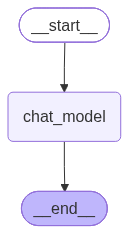

In [22]:
bot

In [23]:
config = {"configurable": {"thread_id": "thread_1"}}
response = bot.invoke({"messages":[HumanMessage(content="Hello, how are you?")]}, config=config)

In [24]:
response

{'messages': [HumanMessage(content='Hello, how are you?', additional_kwargs={}, response_metadata={}, id='d8a641b9-af4a-48b2-ae42-b5ae8b04bb53'),
  AIMessage(content=[{'type': 'text', 'text': "Hello! I'm doing well, thank you for asking. How are you today? How can I help you?", 'extras': {'signature': 'EpUICpIIAWkUfROVxB+pHHPQFNX/kbW6XhBRM4Qq5wpCkfnmsgaNO5gEYocj31oM3//LeMePMUsDbxyBg+maGlvp4ChwzqvV6+dy8PL44VFY7CBBH7Q6UIZc47lbbNvIveISlJYRi/VxOz4xIfljxR0acKeZKtw8NErjvSmNMLeT9CENzrvJh6F+OisawcNquQNSwVm1OiYJo2TgB/XEAhDvdYTNGjlx6Z7UmBAV2KixxI2PlAM6tgjjKkVfUePCoQ/p7pKIqM13D2U7lCZphDljwre2J+GNFd+pkG4AZlsx1gC+7blFYiTzRSVXwZ6NyFmyxzwp6N8XrJBnS9znirm2PFGwwELi0Bf2+BFSGa5Yt9c3SJFoI1P53clIM/zQTEJbXGi01yIVkbBVOkvucfWdrl+T+thSDYg2EX9pFdOMB+mp6b3hN493omb4w1N1eTFPT94bajUOFGdlDDi52fHZiR+QQLN4Bfnt8C0rLE7t6DFgDjKtc8qxtAqHrMNyqzyE15yDmzjiSXE+3n2Lp9ILfpssghMWfCnp3Lp90xqC8jfEBgUp2fnGp+QDtIPJo3Nf/tSmYeThFngHq0jYQmBoOOqsXWxx0/SAzz6Vg+p2SDxe/Kww/zQwRpPJzgdkdLr9Ooz50QCdyRNbhPCXZi02Lg37lZbKpra7r/9LmJBvFxW7xoCPvLNm

In [26]:
bot.invoke({"messages":[HumanMessage(content="my name is rahul?")]}, config=config)

{'messages': [HumanMessage(content='Hello, how are you?', additional_kwargs={}, response_metadata={}, id='d8a641b9-af4a-48b2-ae42-b5ae8b04bb53'),
  AIMessage(content=[{'type': 'text', 'text': "Hello! I'm doing well, thank you for asking. How are you today? How can I help you?", 'extras': {'signature': 'EpUICpIIAWkUfROVxB+pHHPQFNX/kbW6XhBRM4Qq5wpCkfnmsgaNO5gEYocj31oM3//LeMePMUsDbxyBg+maGlvp4ChwzqvV6+dy8PL44VFY7CBBH7Q6UIZc47lbbNvIveISlJYRi/VxOz4xIfljxR0acKeZKtw8NErjvSmNMLeT9CENzrvJh6F+OisawcNquQNSwVm1OiYJo2TgB/XEAhDvdYTNGjlx6Z7UmBAV2KixxI2PlAM6tgjjKkVfUePCoQ/p7pKIqM13D2U7lCZphDljwre2J+GNFd+pkG4AZlsx1gC+7blFYiTzRSVXwZ6NyFmyxzwp6N8XrJBnS9znirm2PFGwwELi0Bf2+BFSGa5Yt9c3SJFoI1P53clIM/zQTEJbXGi01yIVkbBVOkvucfWdrl+T+thSDYg2EX9pFdOMB+mp6b3hN493omb4w1N1eTFPT94bajUOFGdlDDi52fHZiR+QQLN4Bfnt8C0rLE7t6DFgDjKtc8qxtAqHrMNyqzyE15yDmzjiSXE+3n2Lp9ILfpssghMWfCnp3Lp90xqC8jfEBgUp2fnGp+QDtIPJo3Nf/tSmYeThFngHq0jYQmBoOOqsXWxx0/SAzz6Vg+p2SDxe/Kww/zQwRpPJzgdkdLr9Ooz50QCdyRNbhPCXZi02Lg37lZbKpra7r/9LmJBvFxW7xoCPvLNm

In [27]:
bot.invoke({"messages":[HumanMessage(content="what is my name?")]}, config=config)

{'messages': [HumanMessage(content='Hello, how are you?', additional_kwargs={}, response_metadata={}, id='d8a641b9-af4a-48b2-ae42-b5ae8b04bb53'),
  AIMessage(content=[{'type': 'text', 'text': "Hello! I'm doing well, thank you for asking. How are you today? How can I help you?", 'extras': {'signature': 'EpUICpIIAWkUfROVxB+pHHPQFNX/kbW6XhBRM4Qq5wpCkfnmsgaNO5gEYocj31oM3//LeMePMUsDbxyBg+maGlvp4ChwzqvV6+dy8PL44VFY7CBBH7Q6UIZc47lbbNvIveISlJYRi/VxOz4xIfljxR0acKeZKtw8NErjvSmNMLeT9CENzrvJh6F+OisawcNquQNSwVm1OiYJo2TgB/XEAhDvdYTNGjlx6Z7UmBAV2KixxI2PlAM6tgjjKkVfUePCoQ/p7pKIqM13D2U7lCZphDljwre2J+GNFd+pkG4AZlsx1gC+7blFYiTzRSVXwZ6NyFmyxzwp6N8XrJBnS9znirm2PFGwwELi0Bf2+BFSGa5Yt9c3SJFoI1P53clIM/zQTEJbXGi01yIVkbBVOkvucfWdrl+T+thSDYg2EX9pFdOMB+mp6b3hN493omb4w1N1eTFPT94bajUOFGdlDDi52fHZiR+QQLN4Bfnt8C0rLE7t6DFgDjKtc8qxtAqHrMNyqzyE15yDmzjiSXE+3n2Lp9ILfpssghMWfCnp3Lp90xqC8jfEBgUp2fnGp+QDtIPJo3Nf/tSmYeThFngHq0jYQmBoOOqsXWxx0/SAzz6Vg+p2SDxe/Kww/zQwRpPJzgdkdLr9Ooz50QCdyRNbhPCXZi02Lg37lZbKpra7r/9LmJBvFxW7xoCPvLNm